In [2]:
%load_ext autoreload
%autoreload 2

# Plots highlighting the predictability characteristics of LME regions
Investigate in more details the predictability in specific LME regions - are they the same, are they different?

In [3]:
import esm4ppe
import matplotlib.pyplot as plt

### Sort LMEs for predictability

In [4]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','LME','ppp',groupby='month')
ds

<xarray.Dataset>
Dimensions:  (month: 4, lead: 120, region: 66)
Coordinates:
  * month    (month) int64 1 4 7 10
  * lead     (lead) int64 1 2 3 4 5 6 7 8 9 ... 113 114 115 116 117 118 119 120
  * region   (region) <U40 'Baltic Sea' ... 'Northern Bering - Chukchi Seas'
Data variables:
    MLD_003  (month, lead, region) float64 dask.array<chunksize=(4, 120, 66), meta=np.ndarray>
    intpp    (month, lead, region) float64 dask.array<chunksize=(4, 120, 66), meta=np.ndarray>
    no3os    (month, lead, region) float64 dask.array<chunksize=(4, 120, 66), meta=np.ndarray>
    po4os    (month, lead, region) float64 dask.array<chunksize=(4, 120, 66), meta=np.ndarray>
    tos      (month, lead, region) float64 dask.array<chunksize=(4, 120, 66), meta=np.ndarray>

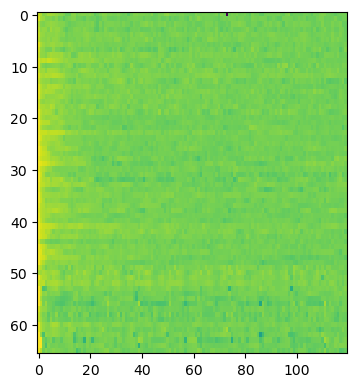

In [5]:
variable = 'intpp'
month=1
da = ds[variable].sel(month=month)

fig,ax = plt.subplots(figsize=(4,12))
ax.imshow(da.T,interpolation='none',aspect=2)

In [7]:
LME_subset = ['California Current','Gulf of California',
              'Pacific Central-American Coastal','Humboldt Current',
              'Canary Current','Guinea Current','Benguela Current']

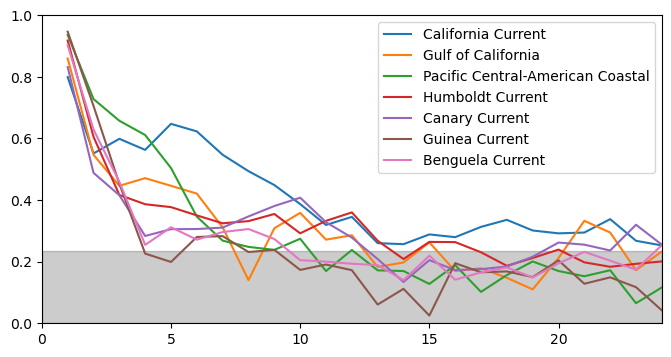

In [17]:
threshold = 0.235559205
fig,ax=plt.subplots(figsize=(8,4))
variable = 'intpp'
month=1
for region in LME_subset:
    ax.plot(ds['lead'],ds[variable].sel(region=region,month=month),label=region)
ax.set_ylim([0,1])
ax.set_xlim([0,24])
ax.legend()
ax.fill_between([0,24],threshold,color='k',alpha=0.2,zorder=0)